# IEEE-CIS Fraud Detection: Tuning Models on Numerical Features
## DSCI 598 Capstone, Week 4
### Ben Miller

Companion notebooks: `bm-fraud-detection-exploratory` and `bm-fraud-baseline-models` (Week 3), and `bm-fraud-numeric-submission` (this week's submission).

# Part 1: Numerical-only models with cross-validated tuning
> Focus on improving your models and earning a higher score than your baseline models from the previous week. Expand your approach to include more advanced forms of preprocessing or modeling.

> To postpone the challenges of categorical features, start by building models that use only the numerical features. Consider logistic regression, decision trees, random forests, and gradient-boosted tree models. Use cross-validation to perform hyperparameter tuning. After identifying the optimal model type and parameters, create a new notebook on Kaggle to submit predictions from this model.

### Decisions for this week

1. **Category codes stored as numbers are held back.** `card1`–`card6`, `addr1`, `addr2` and `id_12`–`id_38` contain numbers, but those numbers are codes for a card, a billing region or a browser, not measurements. Following the recommendation to postpone categorical features, they stay out until the categorical step, along with the text columns. Several of them were in Week 3's top features, so a lower score than Week 3's 0.9227 is possible at this stage. `has_identity` stays in because it's a 0/1 flag.
2. **Tuning uses the full training set.** Every candidate setting is scored on all 590,540 training transactions through time-ordered cross-validation, not a sample. The tradeoff is run time, since this notebook takes several hours, so run it with **Save & Run All** rather than interactively. The one place a sample is used is measuring V-column correlations (100,000 rows). That's a feature-selection step, and 100,000 rows are plenty to measure a correlation.

### Imports, seeds and constants

In [1]:
import os
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Kaggle mounts the competition files here (read-only)
DATA_DIR = '/kaggle/input/competitions/ieee-fraud-detection'

# Column names used throughout
ID_COLUMN = 'TransactionID'
TARGET = 'isFraud'
TIME_COLUMN = 'TransactionDT'      # seconds from an undisclosed starting point, not a real timestamp
AMOUNT_COLUMN = 'TransactionAmt'

# Numerical features (the decision above): measurement-like columns only
NUMERIC_FAMILIES = ['C', 'D', 'V', 'dist']   # counts, time deltas, Vesta features, distances
NUMERIC_IDENTITY_COLUMNS = [f'id_{number:02d}' for number in range(1, 12)]  # id_01-id_11 are measurements; id_12 on are categories
OTHER_NUMERIC_COLUMNS = [AMOUNT_COLUMN, 'has_identity']

# V-column reduction
CORRELATION_SAMPLE_SIZE = 100_000   # rows used to measure correlations (feature selection only, not tuning)
HIGH_CORRELATION = 0.95             # V columns more correlated than this with one already kept are dropped

# Model settings that aren't tuned
TREE_MISSING_VALUE = -999      # scikit-learn trees get missing values replaced by this; it sits below every real value
LOGREG_MAX_ITER = 2000
LIGHTGBM_MAX_ROUNDS = 3000     # upper limit; early stopping picks the real number
EARLY_STOPPING_ROUNDS = 100

# Cross-validation
N_FOLDS = 4          # time-ordered folds; each validates on a later slice of time than it trains on
REVIEW_RATE = 0.01   # analysts review the top 1% of transactions by fraud score
RESULTS_DIR = '.'    # on Kaggle this is /kaggle/working, which keeps files as notebook output
WEEK3_BASELINE_AUC = 0.9227   # Week 3 LightGBM on every column, validated on the most recent 20%

# How many settings to try for each model type; each setting is scored on all N_FOLDS folds
CANDIDATES_PER_MODEL = {
    'logistic_regression': 8,
    'decision_tree': 12,
    'random_forest': 6,     # the slowest model by far, so fewer settings
    'lightgbm': 10,
}

# The settings each search picks from
SEARCH_SPACES = {
    'logistic_regression': {
        'C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],   # smaller C = stronger regularization
        'class_weight': [None, 'balanced'],
    },
    'decision_tree': {
        'max_depth': [4, 6, 8, 10, 12, 15, 20],
        'min_samples_leaf': [10, 50, 100, 250, 500],
        'class_weight': [None, 'balanced'],
    },
    'random_forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [12, 16, 20, 25],
        'min_samples_leaf': [1, 5, 20],
        'max_features': ['sqrt', 'log2'],
        'max_samples': [0.5, 0.8],          # share of rows each tree draws, a standard forest setting
        'class_weight': [None, 'balanced_subsample'],
    },
    'lightgbm': {
        'num_leaves': [31, 63, 127, 255],
        'learning_rate': [0.02, 0.05, 0.1],
        'colsample_bytree': [0.3, 0.5, 0.7],
        'subsample': [0.7, 0.8, 0.9],
        'min_child_samples': [20, 50, 100],
        'reg_lambda': [0.0, 1.0, 5.0],
    },
}

sns.set_theme(style='whitegrid')

### Data-loading functions

The same loading functions as Week 3. Only the training data is needed for tuning.

In [2]:
def downcast_numeric_columns(frame):
    """
    Shrink float64 columns to float32 and integer columns to the smallest type that fits.
    The raw tables need several GB as float64; float32 roughly halves that, and tree
    models don't need the extra precision.
    """
    smaller_types = {}
    for column in frame.columns:
        if pd.api.types.is_float_dtype(frame[column]):
            smaller_types[column] = 'float32'
        elif pd.api.types.is_integer_dtype(frame[column]):
            smallest_fit = pd.to_numeric(frame[column], downcast='integer')
            smaller_types[column] = smallest_fit.dtype

    # one astype call for every column; assigning hundreds of columns one at a time fragments the DataFrame
    return frame.astype(smaller_types)


def standardize_identity_columns(identity):
    """
    Rename test_identity's 'id-01' style columns to train's 'id_01' spelling.
    The competition files use a hyphen in test and an underscore in train, so without
    this every identity feature would silently be missing in test after the merge.
    """
    renamed_columns = {}
    for column in identity.columns:
        if column.startswith('id-'):
            renamed_columns[column] = column.replace('id-', 'id_')
    return identity.rename(columns=renamed_columns)


def load_table(file_name):
    """One competition CSV, with its numeric columns downcast."""
    frame = pd.read_csv(os.path.join(DATA_DIR, file_name))
    return downcast_numeric_columns(frame)


def merge_identity(transactions, identity):
    """
    Left-join identity onto transactions by TransactionID, and flag which rows had a match.
    Only some transactions have identity data, so a left join keeps every transaction and
    leaves the identity columns missing for the rest.
    """
    # mark identity rows before the merge; transactions without a match end up missing, then 0
    flagged_identity = identity.assign(has_identity=1)
    merged = transactions.merge(flagged_identity, on=ID_COLUMN, how='left')
    merged['has_identity'] = merged['has_identity'].fillna(0).astype('int8')
    return merged


def load_split(split_name):
    """The merged transaction + identity table for 'train' or 'test'."""
    transactions = load_table(f'{split_name}_transaction.csv')
    identity = standardize_identity_columns(load_table(f'{split_name}_identity.csv'))
    return merge_identity(transactions, identity)


def memory_mb(frame):
    """How much memory a DataFrame uses, in megabytes."""
    return frame.memory_usage(deep=True).sum() / 1024 ** 2

### Load the training data, ordered by time

Sorting by time once means every fold below can take its training and validation rows by position.

In [3]:
train = load_split('train')
train = train.sort_values(TIME_COLUMN).reset_index(drop=True)
print(f'train: {train.shape[0]:,} rows x {train.shape[1]} columns, {memory_mb(train):,.0f} MB')

train: 590,540 rows x 435 columns, 1,604 MB


### Feature functions

Pick the numerical columns, then drop V columns that nearly duplicate one already kept.

In [4]:
def column_family(column):
    """The feature family a column belongs to, from its name: 'V' for V1-V339, 'dist' for dist1-dist2, and so on."""
    if column.startswith('id_'):
        return 'id'
    return column.rstrip('0123456789')  # 'V258' -> 'V', 'dist1' -> 'dist'


def numeric_feature_columns(frame):
    """
    The measurement-like columns: amount, the identity flag, C, D, V, dist and id_01-id_11.
    Columns that hold category codes stored as numbers (card1-card6, addr1, addr2, id_12 on)
    are left out on purpose, along with the text columns.
    """
    features = []
    for column in frame.columns:
        if column_family(column) in NUMERIC_FAMILIES:
            features.append(column)
        elif column in NUMERIC_IDENTITY_COLUMNS or column in OTHER_NUMERIC_COLUMNS:
            features.append(column)
    return features


def select_uncorrelated_columns(frame, columns, threshold, sample_size):
    """
    Keep one column from each group of near-duplicates, scanning the columns in order.
    A column is dropped when its absolute correlation with a column already kept is above threshold.
    Correlations come from a random sample of rows: plenty to measure a correlation, and much faster than all rows.
    """
    sample = frame[columns].sample(n=min(sample_size, len(frame)), random_state=SEED)
    correlation = sample.corr().abs()
    kept_columns = []
    for column in columns:
        is_near_duplicate = False
        for kept_column in kept_columns:
            if correlation.loc[column, kept_column] > threshold:
                is_near_duplicate = True
                break
        if not is_near_duplicate:
            kept_columns.append(column)
    return kept_columns


def model_feature_columns(frame):
    """The numerical features with redundant V columns removed."""
    numeric_columns = numeric_feature_columns(frame)
    v_columns = []
    other_columns = []
    for column in numeric_columns:
        if column_family(column) == 'V':
            v_columns.append(column)
        else:
            other_columns.append(column)
    kept_v_columns = select_uncorrelated_columns(frame, v_columns, HIGH_CORRELATION, CORRELATION_SAMPLE_SIZE)
    return other_columns + kept_v_columns

### Build the numerical feature set

In [5]:
numeric_columns = numeric_feature_columns(train)
feature_columns = model_feature_columns(train)

held_back = []
for column in train.columns:
    if column not in numeric_columns and column not in [ID_COLUMN, TARGET, TIME_COLUMN]:
        held_back.append(column)

v_before = 0
v_after = 0
for column in numeric_columns:
    if column_family(column) == 'V':
        v_before += 1
for column in feature_columns:
    if column_family(column) == 'V':
        v_after += 1

print(f'{len(numeric_columns)} numerical columns; {v_before - v_after} redundant V columns dropped '
      f'({v_before} -> {v_after})')
print(f'{len(feature_columns)} features used for tuning')
print(f'{len(held_back)} columns held back as categorical, e.g. {held_back[:8]}')

features = train[feature_columns]
target = train[TARGET].to_numpy()

383 numerical columns; 111 redundant V columns dropped (339 -> 228)
272 features used for tuning
49 columns held back as categorical, e.g. ['ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1']


### Time-ordered cross-validation folds

`TimeSeriesSplit` makes each fold train on earlier transactions and validate on the slice right after them, so no fold learns from the future. The last fold trains on the first 80% and validates on the most recent 20%, the same split as Week 3, so its score compares directly with Week 3's 0.9227.

In [6]:
def time_ordered_folds(n_rows, n_folds):
    """(training positions, validation positions) for each fold. Rows must already be sorted by time."""
    splitter = TimeSeriesSplit(n_splits=n_folds)
    return list(splitter.split(np.arange(n_rows)))


folds = time_ordered_folds(len(train), N_FOLDS)
for fold_number, (train_positions, valid_positions) in enumerate(folds, start=1):
    valid_fraud_rate = target[valid_positions].mean()
    print(f'fold {fold_number}: train on {len(train_positions):,} rows, validate on {len(valid_positions):,} '
          f'(fraud rate {valid_fraud_rate:.2%})')

fold 1: train on 118,108 rows, validate on 118,108 (fraud rate 4.01%)
fold 2: train on 236,216 rows, validate on 118,108 (fraud rate 3.75%)
fold 3: train on 354,324 rows, validate on 118,108 (fraud rate 3.90%)
fold 4: train on 472,432 rows, validate on 118,108 (fraud rate 3.44%)


### Evaluation metrics

ROC AUC is the competition metric. The other two describe the review-budget question from the README: if analysts review only the top 1% of transactions by score, what share of all fraud do they catch, and what share of the transactions they review are fraud?

In [7]:
def fraud_caught_at_review_rate(true_labels, fraud_scores, review_rate):
    """Share of all fraud found in the top review_rate of transactions by score."""
    n_reviewed = int(np.ceil(len(fraud_scores) * review_rate))
    reviewed_positions = np.argsort(-fraud_scores)[:n_reviewed]   # sorting the negated scores puts the highest first
    return true_labels[reviewed_positions].sum() / true_labels.sum()


def review_precision_at_review_rate(true_labels, fraud_scores, review_rate):
    """Share of the reviewed transactions that are fraud. The rest are false alarms."""
    n_reviewed = int(np.ceil(len(fraud_scores) * review_rate))
    reviewed_positions = np.argsort(-fraud_scores)[:n_reviewed]
    return true_labels[reviewed_positions].mean()

### Model builders

One builder per model type. Each takes a dictionary of tuned settings and returns an unfitted model. The scikit-learn models are wrapped in a pipeline so missing values are filled inside each fold, using only that fold's training rows.

In [8]:
def build_logistic_regression(params):
    """Median imputation and scaling, since logistic regression handles neither missing values nor mixed scales."""
    return make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(max_iter=LOGREG_MAX_ITER, **params),   # ** passes each tuned setting as its own argument
    )


def build_decision_tree(params):
    """A single decision tree, with missing values replaced by a stand-in value."""
    return make_pipeline(
        SimpleImputer(strategy='constant', fill_value=TREE_MISSING_VALUE),
        DecisionTreeClassifier(random_state=SEED, **params),
    )


def build_random_forest(params):
    """A random forest, with missing values replaced by a stand-in value. n_jobs=-1 uses every CPU core."""
    return make_pipeline(
        SimpleImputer(strategy='constant', fill_value=TREE_MISSING_VALUE),
        RandomForestClassifier(random_state=SEED, n_jobs=-1, **params),
    )


def build_lightgbm(params):
    """LightGBM handles missing values itself. Its tree count is a ceiling that early stopping cuts short."""
    return lgb.LGBMClassifier(
        n_estimators=LIGHTGBM_MAX_ROUNDS,
        subsample_freq=1,      # subsample only takes effect when this is 1 or more
        metric='auc',          # early stopping watches AUC, not the default log loss
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
        **params,
    )


MODEL_BUILDERS = {
    'logistic_regression': build_logistic_regression,
    'decision_tree': build_decision_tree,
    'random_forest': build_random_forest,
    'lightgbm': build_lightgbm,
}

### Cross-validation and tuning functions

`cross_validate_candidate` scores one group of settings on every fold. `tune_model` tries several groups for one model type and saves the results as a CSV. If that CSV already exists (from earlier in the same session), it loads it instead of retraining.

LightGBM early-stops on each fold's validation slice, which is standard practice. It makes its scores very slightly optimistic, since that slice also picks the number of trees.

In [9]:
def fit_on_fold(model_name, params, train_features, train_target, valid_features, valid_target):
    """Fit one model on one fold's training rows. LightGBM also early-stops on the fold's validation rows."""
    model = MODEL_BUILDERS[model_name](params)
    if model_name == 'lightgbm':
        model.fit(
            train_features,
            train_target,
            eval_set=[(valid_features, valid_target)],
            callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)],
        )
    else:
        model.fit(train_features, train_target)
    return model


def cross_validate_candidate(model_name, params, features, target, folds):
    """Average scores for one group of settings across every fold, plus the last fold's AUC and the run time."""
    start_time = time.time()
    fold_aucs = []
    fold_fraud_caught = []
    fold_review_precision = []
    fold_trees = []
    for train_positions, valid_positions in folds:
        train_features = features.iloc[train_positions]
        valid_features = features.iloc[valid_positions]
        train_target = target[train_positions]
        valid_target = target[valid_positions]

        model = fit_on_fold(model_name, params, train_features, train_target, valid_features, valid_target)
        fraud_scores = model.predict_proba(valid_features)[:, 1]

        fold_aucs.append(roc_auc_score(valid_target, fraud_scores))
        fold_fraud_caught.append(fraud_caught_at_review_rate(valid_target, fraud_scores, REVIEW_RATE))
        fold_review_precision.append(review_precision_at_review_rate(valid_target, fraud_scores, REVIEW_RATE))
        if model_name == 'lightgbm':
            fold_trees.append(model.best_iteration_)

    scores = {
        'mean_auc': np.mean(fold_aucs),
        'std_auc': np.std(fold_aucs),
        'last_fold_auc': fold_aucs[-1],
        'fraud_caught_top_1pct': np.mean(fold_fraud_caught),
        'review_precision_top_1pct': np.mean(fold_review_precision),
        'minutes': (time.time() - start_time) / 60,
    }
    if fold_trees:
        scores['mean_trees'] = int(np.mean(fold_trees))
    return scores


def tune_model(model_name, n_candidates):
    """
    Score n_candidates randomly chosen settings for one model type, best first.
    Results are saved to a CSV, and loaded from it on a rerun in the same session.
    """
    results_path = os.path.join(RESULTS_DIR, f'tuning_{model_name}.csv')
    if os.path.exists(results_path):
        print(f'Found {results_path}, loading saved results instead of retraining')
        return pd.read_csv(results_path)

    candidates = list(ParameterSampler(SEARCH_SPACES[model_name], n_iter=n_candidates, random_state=SEED))
    rows = []
    for candidate_number, params in enumerate(candidates, start=1):
        scores = cross_validate_candidate(model_name, params, features, target, folds)
        row = {'model': model_name, 'params': json.dumps(params)}
        row.update(scores)
        rows.append(row)
        print(f"{model_name} {candidate_number}/{len(candidates)}: mean AUC {scores['mean_auc']:.4f}, "
              f"{scores['minutes']:.1f} min, {params}")

    results = pd.DataFrame(rows).sort_values('mean_auc', ascending=False).reset_index(drop=True)
    results.to_csv(results_path, index=False)
    return results


def show_top_candidates(results, top_n):
    """The top_n settings for one model type, with their scores."""
    columns = ['mean_auc', 'std_auc', 'last_fold_auc', 'fraud_caught_top_1pct', 'review_precision_top_1pct', 'minutes', 'params']
    print(results[columns].head(top_n).round(4).to_string(index=False))

### Tune logistic regression

The fastest model, and the linear baseline.

In [10]:
logreg_results = tune_model('logistic_regression', CANDIDATES_PER_MODEL['logistic_regression'])
show_top_candidates(logreg_results, 3)

logistic_regression 1/8: mean AUC 0.8235, 1.1 min, {'class_weight': None, 'C': 0.001}
logistic_regression 2/8: mean AUC 0.8317, 1.5 min, {'class_weight': 'balanced', 'C': 0.001}
logistic_regression 3/8: mean AUC 0.8243, 2.2 min, {'class_weight': None, 'C': 0.1}
logistic_regression 4/8: mean AUC 0.8305, 2.3 min, {'class_weight': 'balanced', 'C': 0.01}
logistic_regression 5/8: mean AUC 0.8311, 1.8 min, {'class_weight': 'balanced', 'C': 0.003}
logistic_regression 6/8: mean AUC 0.8314, 4.6 min, {'class_weight': 'balanced', 'C': 1.0}
logistic_regression 7/8: mean AUC 0.8241, 3.0 min, {'class_weight': None, 'C': 10.0}
logistic_regression 8/8: mean AUC 0.8313, 4.8 min, {'class_weight': 'balanced', 'C': 3.0}
 mean_auc  std_auc  last_fold_auc  fraud_caught_top_1pct  review_precision_top_1pct  minutes                                   params
   0.8317   0.0124         0.8216                 0.1589                     0.6123   1.4565 {"class_weight": "balanced", "C": 0.001}
   0.8314   0.0162    

### Tune a decision tree

A single tree, mainly to show how much the ensembles below gain from combining many trees.

In [11]:
tree_results = tune_model('decision_tree', CANDIDATES_PER_MODEL['decision_tree'])
show_top_candidates(tree_results, 3)

decision_tree 1/12: mean AUC 0.8295, 1.0 min, {'min_samples_leaf': 100, 'max_depth': 12, 'class_weight': None}
decision_tree 2/12: mean AUC 0.6816, 0.4 min, {'min_samples_leaf': 10, 'max_depth': 4, 'class_weight': None}
decision_tree 3/12: mean AUC 0.8261, 0.7 min, {'min_samples_leaf': 500, 'max_depth': 8, 'class_weight': 'balanced'}
decision_tree 4/12: mean AUC 0.7106, 0.4 min, {'min_samples_leaf': 500, 'max_depth': 4, 'class_weight': None}
decision_tree 5/12: mean AUC 0.8351, 0.9 min, {'min_samples_leaf': 500, 'max_depth': 10, 'class_weight': 'balanced'}
decision_tree 6/12: mean AUC 0.8155, 0.9 min, {'min_samples_leaf': 250, 'max_depth': 10, 'class_weight': None}
decision_tree 7/12: mean AUC 0.7757, 0.8 min, {'min_samples_leaf': 10, 'max_depth': 8, 'class_weight': None}
decision_tree 8/12: mean AUC 0.8298, 1.4 min, {'min_samples_leaf': 250, 'max_depth': 20, 'class_weight': None}
decision_tree 9/12: mean AUC 0.8034, 0.8 min, {'min_samples_leaf': 10, 'max_depth': 8, 'class_weight': 'ba

### Tune a random forest

The slowest search: every setting trains up to 300 trees on each of the four folds.

In [12]:
forest_results = tune_model('random_forest', CANDIDATES_PER_MODEL['random_forest'])
show_top_candidates(forest_results, 3)

random_forest 1/6: mean AUC 0.8686, 2.7 min, {'n_estimators': 100, 'min_samples_leaf': 1, 'max_samples': 0.8, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': None}
random_forest 2/6: mean AUC 0.8624, 4.2 min, {'n_estimators': 200, 'min_samples_leaf': 5, 'max_samples': 0.8, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'}
random_forest 3/6: mean AUC 0.8565, 4.4 min, {'n_estimators': 200, 'min_samples_leaf': 5, 'max_samples': 0.5, 'max_features': 'sqrt', 'max_depth': 25, 'class_weight': 'balanced_subsample'}
random_forest 4/6: mean AUC 0.8691, 2.0 min, {'n_estimators': 100, 'min_samples_leaf': 20, 'max_samples': 0.5, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': None}
random_forest 5/6: mean AUC 0.8456, 3.6 min, {'n_estimators': 200, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': 'balanced_subsample'}
random_forest 6/6: mean AUC 0.8613, 2.1 min, {'n_estimators': 100, 'min_samples_leaf':

### Tune LightGBM

Gradient-boosted trees, with early stopping picking the number of trees on each fold.

In [13]:
lightgbm_results = tune_model('lightgbm', CANDIDATES_PER_MODEL['lightgbm'])
show_top_candidates(lightgbm_results, 3)

lightgbm 1/10: mean AUC 0.8901, 2.2 min, {'subsample': 0.9, 'reg_lambda': 0.0, 'num_leaves': 63, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
lightgbm 2/10: mean AUC 0.8926, 5.0 min, {'subsample': 0.8, 'reg_lambda': 5.0, 'num_leaves': 255, 'min_child_samples': 50, 'learning_rate': 0.02, 'colsample_bytree': 0.3}
lightgbm 3/10: mean AUC 0.8893, 2.4 min, {'subsample': 0.7, 'reg_lambda': 0.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
lightgbm 4/10: mean AUC 0.8901, 3.8 min, {'subsample': 0.9, 'reg_lambda': 5.0, 'num_leaves': 63, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.5}
lightgbm 5/10: mean AUC 0.8872, 2.2 min, {'subsample': 0.9, 'reg_lambda': 1.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
lightgbm 6/10: mean AUC 0.8908, 2.9 min, {'subsample': 0.8, 'reg_lambda': 1.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.05,

### Compare the best setting of each model type

Mean AUC across the four folds, with error bars showing the spread between folds. The last-fold AUC is the one to compare with Week 3's 0.9227, since it uses the same split.

              model  mean_auc  std_auc  last_fold_auc  fraud_caught_top_1pct  review_precision_top_1pct
           lightgbm    0.8926   0.0107         0.8960                 0.2444                     0.9203
      random_forest    0.8691   0.0082         0.8664                 0.2342                     0.8822
      decision_tree    0.8351   0.0107         0.8377                 0.1850                     0.6988
logistic_regression    0.8317   0.0124         0.8216                 0.1589                     0.6123

Week 3 baseline (all columns, same split as the last fold): 0.9227


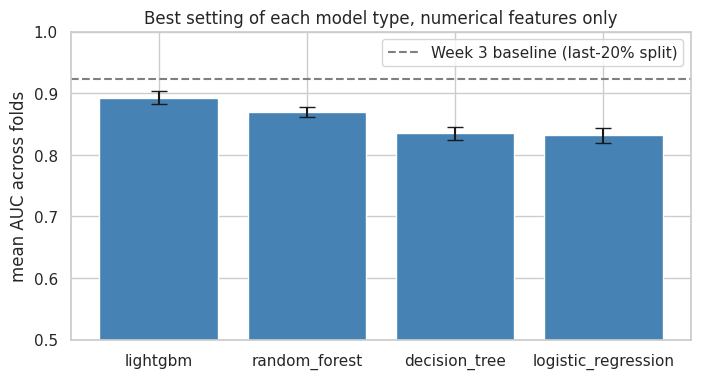

In [14]:
def best_of_each_model(results_tables):
    """The top row of each model type's tuning results, best model first."""
    best_rows = []
    for results in results_tables:
        best_rows.append(results.iloc[0])
    return pd.DataFrame(best_rows).sort_values('mean_auc', ascending=False).reset_index(drop=True)


comparison = best_of_each_model([logreg_results, tree_results, forest_results, lightgbm_results])
summary_columns = ['model', 'mean_auc', 'std_auc', 'last_fold_auc', 'fraud_caught_top_1pct', 'review_precision_top_1pct']
print(comparison[summary_columns].round(4).to_string(index=False))
print(f'\nWeek 3 baseline (all columns, same split as the last fold): {WEEK3_BASELINE_AUC}')

plt.figure(figsize=(8, 4))
plt.bar(comparison['model'], comparison['mean_auc'], yerr=comparison['std_auc'], capsize=6, color='steelblue')
plt.axhline(WEEK3_BASELINE_AUC, linestyle='--', color='gray', label='Week 3 baseline (last-20% split)')
plt.ylim(0.5, 1.0)
plt.ylabel('mean AUC across folds')
plt.title('Best setting of each model type, numerical features only')
plt.legend()
plt.show()

### Best model and settings for the submission notebook

In [15]:
best = comparison.iloc[0]
best_trees = None
if best['model'] == 'lightgbm':
    best_trees = int(best['mean_trees'])

print(f"BEST_MODEL_NAME = '{best['model']}'")
print(f"BEST_PARAMS = {json.loads(best['params'])}")
print(f'BEST_N_ESTIMATORS = {best_trees}   # LightGBM only: average number of trees early stopping chose')

BEST_MODEL_NAME = 'lightgbm'
BEST_PARAMS = {'subsample': 0.8, 'reg_lambda': 5.0, 'num_leaves': 255, 'min_child_samples': 50, 'learning_rate': 0.02, 'colsample_bytree': 0.3}
BEST_N_ESTIMATORS = 327   # LightGBM only: average number of trees early stopping chose


### What tuning showed

- Best model type: **LightGBM**, with a mean AUC of **0.8926** across four folds (standard deviation 0.0107) and a last-fold AUC of **0.8960**, compared with Week 3's 0.9227.
- Fraud caught reviewing the top 1%: **24.4%** of all fraud, with **92.0%** of reviewed transactions being fraud. Since fraud is 3.4–4.0% of each validation fold, reviewing 1% of transactions can catch at most about 25–29% of the fraud, so LightGBM is close to that ceiling.
- Logistic regression, decision tree and random forest best mean AUCs: **0.8317**, **0.8351** and **0.8691**. The ranking matches what I expected: LightGBM, then random forest, then a single tree and logistic regression about even.
- Logistic regression improved a lot over Week 3, from 0.7787 to 0.8216 on the same last-20% split, because it now has 272 columns instead of 17.
- Holding back the categorical-style columns cost about **0.027 AUC** on the last-20% split (0.8960 vs. 0.9227). That's most likely `card1`, `card2`, `addr1` and the other held-back columns, several of which were in Week 3's top features. It suggests the categorical step should recover most of that gap.